# Find the information probabilities miss

Two state vectors can give the same probabilities for one measurement and still differ in relative phase. This notebook makes that distinction visible with complex arrows and an explicitly defined second measurement basis.

The starting outcome basis is `[0, 1]`. We will introduce the alternate outcomes **plus** and **minus** before using their matrix. No previous knowledge of quantum gates is required.

## 1. Prepare the workspace

Use complex NumPy arrays for the amplitudes. All examples below are normalized. The graphs describe mathematical state amplitudes and measurement predictions, not trajectories through physical space.

In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

plt.rcParams.update(
    {
        "figure.figsize": (8.4, 3.8),
        "figure.dpi": 120,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.labelcolor": "#24354b",
        "text.color": "#24354b",
        "xtick.color": "#44556c",
        "ytick.color": "#44556c",
        "font.size": 11,
        "axes.titleweight": "bold",
        "axes.grid": True,
        "grid.alpha": 0.16,
        "grid.color": "#718198",
        "lines.linewidth": 2.4,
        "savefig.bbox": "tight",
    }
)
BLUE, GREEN, AMBER = "#3c6db3", "#27836d", "#b87920"
rng = np.random.default_rng(20261015)
print(f"Ready: NumPy {np.__version__}, Matplotlib {matplotlib.__version__}")
print("All plots below come from the code in this notebook.")

Ready: NumPy 2.5.4, Matplotlib 3.11.2
All plots below come from the code in this notebook.


## 2. Rotate a complex arrow without changing its length

The expression `exp(1j * phase)` has magnitude one. Multiplying an amplitude by it rotates that amplitude in the complex plane.

Here the amplitude has fixed magnitude `1/sqrt(2)`. Predict its squared magnitude at `0°`, `90°`, and `180°`. Rotating a single arrow changes its phase but leaves its contribution's squared magnitude at `1/2`.

  0°: amplitude = +0.707+0.000i; squared magnitude = 0.500
 90°: amplitude = +0.000+0.707i; squared magnitude = 0.500
180°: amplitude = -0.707+0.000i; squared magnitude = 0.500


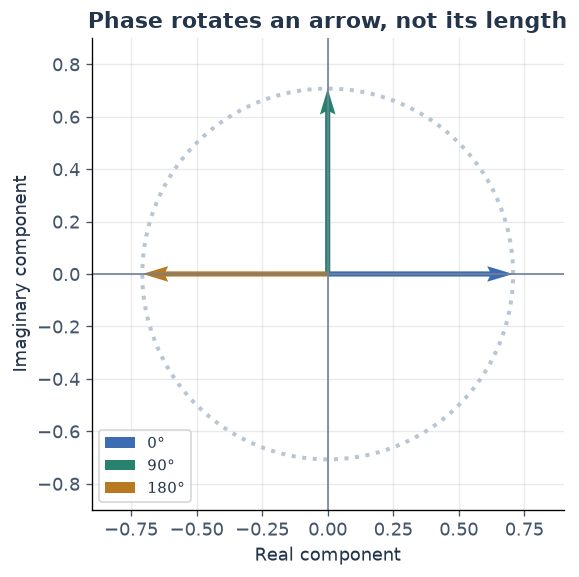

In [2]:
phase_degrees = np.array([0, 90, 180])
arrows = np.exp(1j * np.deg2rad(phase_degrees)) / np.sqrt(2)
fig, ax = plt.subplots(figsize=(6.0, 4.7), layout="constrained")
circle_angle = np.linspace(0, 2 * np.pi, 361)
ax.plot(
    np.cos(circle_angle) / np.sqrt(2),
    np.sin(circle_angle) / np.sqrt(2),
    color="#bac5d4",
    linestyle=":",
)
for phase, z, color in zip(phase_degrees, arrows, [BLUE, GREEN, AMBER]):
    ax.quiver(
        0,
        0,
        z.real,
        z.imag,
        angles="xy",
        scale_units="xy",
        scale=1,
        color=color,
        width=0.011,
        label=f"{phase}°",
    )
    print(
        f"{phase:3d}°: amplitude = {z.real:+.3f}{z.imag:+.3f}i; squared magnitude = "
        f"{abs(z) ** 2:.3f}"
    )
ax.axhline(0, color="#718198", linewidth=1)
ax.axvline(0, color="#718198", linewidth=1)
ax.set(
    xlabel="Real component",
    ylabel="Imaginary component",
    xlim=(-0.9, 0.9),
    ylim=(-0.9, 0.9),
    aspect="equal",
    title="Phase rotates an arrow, not its length",
)
ax.legend(loc="lower left", fontsize=9)
plt.show()
assert np.allclose(np.abs(arrows) ** 2, 0.5)

## 3. Find two states with the same direct probabilities

Compare the normalized vectors `[1, 1]/sqrt(2)` and `[1, -1]/sqrt(2)`. In the outcome basis `[0, 1]`, both give `[0.5, 0.5]`.

The first has relative phase `0°`; the second has relative phase `180°`. Squaring magnitudes loses this distinction. Relative phase means the angle difference between the two amplitudes, not the sign of a probability.

Aligned  amplitudes: [0.707107+0.j 0.707107+0.j]
Aligned  outcome [0, 1] probabilities: [0.5 0.5]
Opposite amplitudes: [ 0.707107+0.j -0.707107+0.j]
Opposite outcome [0, 1] probabilities: [0.5 0.5]


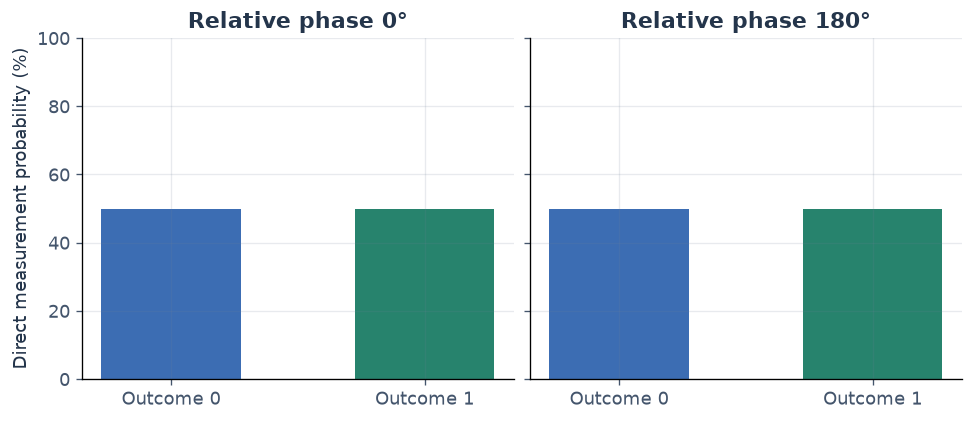

In [3]:
psi_aligned = np.array([1, 1], dtype=complex) / np.sqrt(2)
psi_opposite = np.array([1, -1], dtype=complex) / np.sqrt(2)


def probabilities(state):
    result = np.abs(state) ** 2
    assert np.isclose(result.sum(), 1)
    return result


for name, state in [("Aligned", psi_aligned), ("Opposite", psi_opposite)]:
    print(f"{name:8s} amplitudes: {np.round(state, 6)}")
    print(f"{name:8s} outcome [0, 1] probabilities: {probabilities(state)}")
assert np.allclose(probabilities(psi_aligned), probabilities(psi_opposite))
assert not np.allclose(psi_aligned, psi_opposite)
fig, axes = plt.subplots(1, 2, figsize=(8.0, 3.4), layout="constrained", sharey=True)
for ax, state, title in zip(
    axes, [psi_aligned, psi_opposite], ["Relative phase 0°", "Relative phase 180°"]
):
    ax.bar(
        ["Outcome 0", "Outcome 1"],
        100 * probabilities(state),
        color=[BLUE, GREEN],
        width=0.55,
    )
    ax.set(title=title, ylim=(0, 100))
axes[0].set_ylabel("Direct measurement probability (%)")
plt.show()

## 4. Define a measurement that can see the difference

Use two new orthonormal basis vectors: `plus = [1, 1]/sqrt(2)` and `minus = [1, -1]/sqrt(2)`. They are unit vectors with zero overlap. The two new measurement outcomes are labelled **plus** and **minus**.

For an input state, its amplitude for a new basis outcome is that basis vector's complex inner product with the state. NumPy's `vdot` conjugates its first argument. The matrix `H` below collects those two inner products into one operation, `H @ state`; its entries are just `1/sqrt(2)` and `-1/sqrt(2)`.

This matrix is called the Hadamard matrix. Here we use it to calculate coordinates for a measurement in the plus/minus basis. Later lessons can implement the equivalent measurement by applying a Hadamard gate and then measuring in the original 0/1 basis.

Aligned state: plus/minus amplitudes = [1.+0.j 0.+0.j]
Aligned state: plus/minus probabilities = [1. 0.]
Opposite state: plus/minus amplitudes = [0.+0.j 1.+0.j]
Opposite state: plus/minus probabilities = [0. 1.]


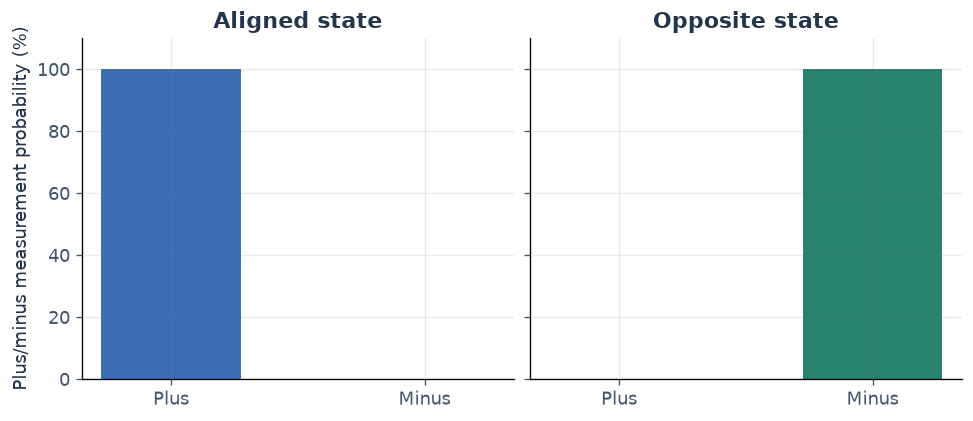

In [4]:
plus_basis = np.array([1, 1], dtype=complex) / np.sqrt(2)
minus_basis = np.array([1, -1], dtype=complex) / np.sqrt(2)
H = np.vstack([plus_basis.conj(), minus_basis.conj()])
assert np.isclose(np.vdot(plus_basis, minus_basis), 0)
assert np.allclose(H.conj().T @ H, np.eye(2))


def plus_minus_probabilities(state):
    amplitudes = H @ state
    return probabilities(amplitudes)


fig, axes = plt.subplots(1, 2, figsize=(8.0, 3.4), layout="constrained", sharey=True)
for ax, name, state, color in zip(
    axes,
    ["Aligned state", "Opposite state"],
    [psi_aligned, psi_opposite],
    [BLUE, GREEN],
):
    via_inner_products = np.array(
        [np.vdot(plus_basis, state), np.vdot(minus_basis, state)]
    )
    assert np.allclose(via_inner_products, H @ state)
    p_new = plus_minus_probabilities(state)
    print(f"{name}: plus/minus amplitudes = {np.round(H @ state, 6)}")
    print(f"{name}: plus/minus probabilities = {np.round(p_new, 6)}")
    ax.bar(["Plus", "Minus"], 100 * p_new, color=color, width=0.55)
    ax.set(title=name, ylim=(0, 110))
axes[0].set_ylabel("Plus/minus measurement probability (%)")
plt.show()
assert np.allclose(plus_minus_probabilities(psi_aligned), [1, 0])
assert np.allclose(plus_minus_probabilities(psi_opposite), [0, 1])

## 5. Turn relative phase into a measurable change

Form the family of states `[1, exp(i * phase)]/sqrt(2)`. Their direct outcome probabilities remain `[0.5, 0.5]`. Their plus/minus probabilities vary continuously with relative phase.

In this basis, the plus amplitude is `(1 + exp(i * phase))/2`: add two contributions, then square the magnitude. Predict the plus probability at `0°`, `90°`, and `180°`. At `90°`, neither perfect reinforcement nor perfect cancellation occurs.

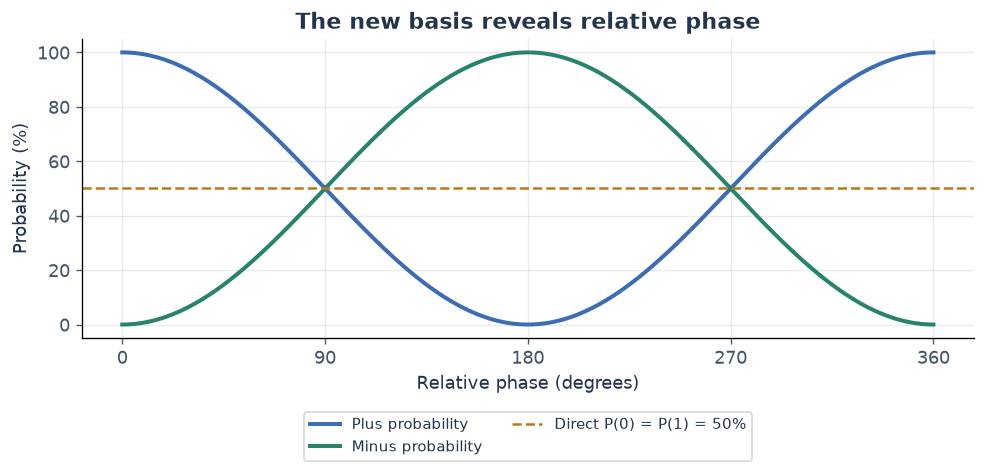

  0° relative phase: P(plus) = 1.00, P(minus) = 0.00
 90° relative phase: P(plus) = 0.50, P(minus) = 0.50
180° relative phase: P(plus) = 0.00, P(minus) = 1.00


In [5]:
phase_sweep = np.linspace(0, 360, 361)
plus_probabilities = []
minus_probabilities = []
for phase in phase_sweep:
    state = np.array([1, np.exp(1j * np.deg2rad(phase))]) / np.sqrt(2)
    p_new = plus_minus_probabilities(state)
    plus_probabilities.append(p_new[0])
    minus_probabilities.append(p_new[1])
plus_probabilities = np.array(plus_probabilities)
minus_probabilities = np.array(minus_probabilities)
assert np.allclose(plus_probabilities + minus_probabilities, 1)
assert np.allclose(plus_probabilities, (1 + np.cos(np.deg2rad(phase_sweep))) / 2)
fig, ax = plt.subplots(figsize=(8.1, 3.8), layout="constrained")
ax.plot(phase_sweep, 100 * plus_probabilities, color=BLUE, label="Plus probability")
ax.plot(phase_sweep, 100 * minus_probabilities, color=GREEN, label="Minus probability")
ax.axhline(
    50, color=AMBER, linestyle="--", linewidth=1.5, label="Direct P(0) = P(1) = 50%"
)
ax.set(
    xlabel="Relative phase (degrees)",
    ylabel="Probability (%)",
    title="The new basis reveals relative phase",
    xticks=[0, 90, 180, 270, 360],
    ylim=(-5, 105),
)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2, fontsize=9)
plt.show()
for phase in [0, 90, 180]:
    print(
        f"{phase:3d}° relative phase: P(plus) = {plus_probabilities[phase]:.2f}, "
        f"P(minus) = {minus_probabilities[phase]:.2f}"
    )

## 6. Separate global phase from relative phase

A **global phase** rotates every amplitude by the same angle. Multiplying an entire state by `exp(i * global_phase)` leaves its relative phase unchanged and leaves every measurement prediction unchanged.

Check both bases for one state. The amplitudes change, but their measurement probabilities do not. This differs from rotating just the second entry, which changed the relative phase in the previous section.

In [6]:
state = np.array([np.sqrt(0.3), np.exp(1j * np.deg2rad(70)) * np.sqrt(0.7)])
global_phase_deg = 137
rotated_state = np.exp(1j * np.deg2rad(global_phase_deg)) * state
print("Original amplitudes:", np.round(state, 6))
print("After a shared 137° rotation:", np.round(rotated_state, 6))
for name, original_p, rotated_p in [
    ("Direct [0, 1]", probabilities(state), probabilities(rotated_state)),
    (
        "Plus/minus",
        plus_minus_probabilities(state),
        plus_minus_probabilities(rotated_state),
    ),
]:
    print(
        f"{name}: original {np.round(original_p, 6)}, rotated {np.round(rotated_p, 6)}"
    )
    assert np.allclose(original_p, rotated_p)
original_relative = np.angle(state[1] / state[0], deg=True)
rotated_relative = np.angle(rotated_state[1] / rotated_state[0], deg=True)
print(
    f"Relative phase before / after: {original_relative:.1f}° / {rotated_relative:.1f}°"
)
assert np.isclose(original_relative, rotated_relative)
print(
    "Reason for every basis: a shared unit-magnitude factor passes through the linear "
    "inner product, then disappears when taking squared magnitude."
)

Original amplitudes: [0.547723+0.j       0.286155+0.786203j]
After a shared 137° rotation: [-0.400579+0.373546j -0.74547 -0.379836j]
Direct [0, 1]: original [0.3 0.7], rotated [0.3 0.7]
Plus/minus: original [0.656733 0.343267], rotated [0.656733 0.343267]
Relative phase before / after: 70.0° / 70.0°
Reason for every basis: a shared unit-magnitude factor passes through the linear inner product, then disappears when taking squared magnitude.


## 7. Check the full chain with a new phase

Try relative phase `120°` in the equal-magnitude state. Before reading the output, predict the direct probabilities and the plus/minus probabilities. The plus amplitude is the average of two phase arrows; its squared magnitude gives `0.25`.

Then add a shared global rotation of `40°`. The result should remain unchanged in both measurement bases. These assertions are numerical checks of the distinction you just learned.

In [7]:
test_state = np.array([1, np.exp(1j * np.deg2rad(120))]) / np.sqrt(2)
direct_p = probabilities(test_state)
alternate_p = plus_minus_probabilities(test_state)
shared_rotation = np.exp(1j * np.deg2rad(40)) * test_state
print("At relative phase 120°:")
print("Direct [0, 1] probabilities:", np.round(direct_p, 6))
print("Plus/minus probabilities:", np.round(alternate_p, 6))
print(
    "After shared 40° rotation:", np.round(plus_minus_probabilities(shared_rotation), 6)
)
assert np.allclose(direct_p, [0.5, 0.5])
assert np.allclose(alternate_p, [0.25, 0.75])
assert np.allclose(probabilities(shared_rotation), direct_p)
assert np.allclose(plus_minus_probabilities(shared_rotation), alternate_p)
print(
    "All checks passed: normalization, relative-phase sensitivity, and global-phase "
    "invariance."
)

At relative phase 120°:
Direct [0, 1] probabilities: [0.5 0.5]
Plus/minus probabilities: [0.25 0.75]
After shared 40° rotation: [0.25 0.75]
All checks passed: normalization, relative-phase sensitivity, and global-phase invariance.


**Take this with you:** a state's probabilities depend on the measurement basis. Relative phase can change interference and become visible in another basis. A shared global phase does not change measurement predictions.

**Try a change locally:** replace `120°` with `60°`. Predict the plus/minus probabilities before running. Then change the two magnitudes from equal to `sqrt(0.2)` and `sqrt(0.8)` and repeat the sweep. Both direct probabilities still stay fixed as phase changes, but the plus/minus curve no longer reaches both certainty and impossibility.

Reference: [IBM, fundamentals of quantum information](https://quantum.cloud.ibm.com/learning/courses/basics-of-quantum-information).